In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageII_raw.mtx').T

In [3]:
adata.X.max()

3499.0

In [4]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageII_raw_cellnames.csv")["x"]

In [5]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageII_raw_genenames.csv")["x"]

In [6]:
adata.obs_names = cellnames
adata.var_names = genenames

In [7]:
family_info = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/stemdata_stageII_metatable.csv')

In [8]:
family_info = family_info.set_index("Unnamed: 0")
family_info

,Sample,Cell.Barcode,Virus.Barcode,Cluster.Id
Unnamed: 0,,,,
AAACCCAAGGTAGCCA-1_1,Stage_II_Exp1,AAACCCAAGGTAGCCA-1_1,NaN,NaN
AAACCCAAGTCACACT-1_1,Stage_II_Exp1,AAACCCAAGTCACACT-1_1,NaN,NaN
AAACCCACAAAGTATG-1_1,Stage_II_Exp1,AAACCCACAAAGTATG-1_1,NaN,NaN
AAACCCACAAGGATGC-1_1,Stage_II_Exp1,AAACCCACAAGGATGC-1_1,NaN,NaN
AAACCCACATGTGGTT-1_1,Stage_II_Exp1,AAACCCACATGTGGTT-1_1,GTGTCTGTCTGACTCTGTGTCTGTCTGTGTGT-1-1,II-Motors
...,...,...,...,...
TTTGTTGGTGTTCGTA-1_8,Stage_II_Rep2_Exp2,TTTGTTGGTGTTCGTA-1_8,NaN,NaN
TTTGTTGTCACTTTGT-1_8,Stage_II_Rep2_Exp2,TTTGTTGTCACTTTGT-1_8,NaN,NaN
TTTGTTGTCCACGTAA-1_8,Stage_II_Rep2_Exp2,TTTGTTGTCCACGTAA-1_8,NaN,NaN


In [9]:
adata.obs["barcode"] = adata.obs_names.map(family_info["Virus.Barcode"])

In [10]:
adata.obs["barcode"]

x
AAACCCAAGGTAGCCA-1_1                                     NaN
AAACCCAAGTCACACT-1_1                                     NaN
AAACCCACAAAGTATG-1_1                                     NaN
AAACCCACAAGGATGC-1_1                                     NaN
AAACCCACATGTGGTT-1_1    GTGTCTGTCTGACTCTGTGTCTGTCTGTGTGT-1-1
                                        ...                 
TTTGTTGGTGTTCGTA-1_8                                     NaN
TTTGTTGTCACTTTGT-1_8                                     NaN
TTTGTTGTCCACGTAA-1_8                                     NaN
TTTGTTGTCCAGTTCC-1_8                                     NaN
TTTGTTGTCTCGAACA-1_8                                     NaN
Name: barcode, Length: 91964, dtype: object

In [11]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [12]:
adata_no_nan

View of AnnData object with n_obs × n_vars = 43424 × 27317
    obs: 'barcode'

In [13]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

/tmp/ipykernel_2741282/2707677046.py:4: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")


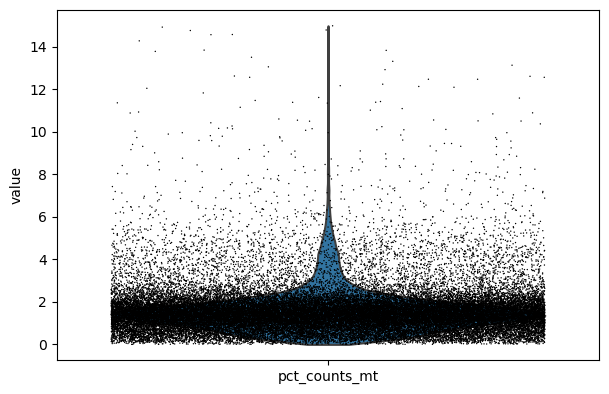

In [14]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [15]:
# Filter cells with >5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 5].copy()

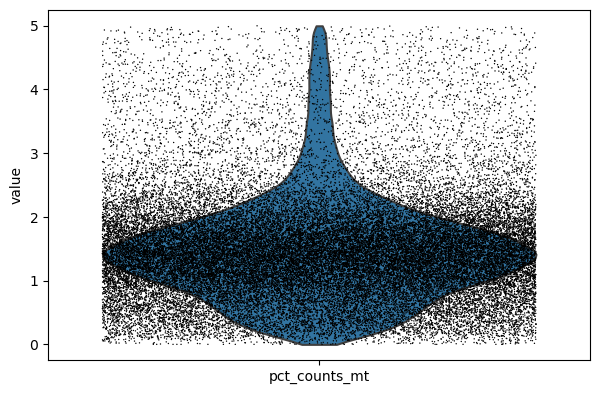

In [16]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [17]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [18]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [19]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [20]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [21]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [22]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [23]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [24]:
df

x,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP5-857K21.4,RP11-206L10.9,FAM87B,LINC00115,FAM41C,RP11-54O7.16,...,POTEH,CTA-243E7.2,CTA-992D9.8,RP11-46E17.6,RP1-302D9.3,PRR34-AS1,AF212831.2,AP000470.2,barcode,barcode_cont
0,0.0,0.356834,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTCTGTCTGACTCTGTGTCTGTCTGTGTGT-1-1,0
1,0.0,0.000000,0.384491,0.0,0.000000,0.384491,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTCTGTGTGTGTGAGTCTGTGTCTCTGTGTGT-1-1;CAGTGAGTC...,1
2,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTGAGACTGTGACTGTGTGTCTCTCTGTCT-1-1,2
3,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTCTCTGTGTGTGTCTCTCTGTCAGTCTCT-1-1,3
4,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTGTCTGTGTCTCAGTGTGTCTCACTGTCA-1-1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42635,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT-3-2;CTCTGACAC...,33303
42636,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTGTGTGACACAGACTGTGTGTGTCAGTGT-3-2,33304
42637,0.0,0.000000,0.000000,0.0,0.677093,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTCTGTGTGAGACAGTGTGTCTCTCAGTGACT-3-2;CCCCGTGCG...,33305
42638,0.0,0.756515,0.756515,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTGTGTGTGACAGTGTGTCAGTCTGTGTCT-3-2,33306


In [25]:
df = df.drop("barcode", axis=1)

In [26]:
df.to_pickle('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl')
